# FINAL_LOGISTICS — Reconstitution du volet logistique de l'incident KNT-KES

Ce notebook constitue le volet **Logistics** de l'investigation présentée dans `FINAL_ECOLOGY.ipynb`. Il reprend sa démarche : partir d'un événement d'intérêt, identifier les enregistrements pertinents, consolider les tables qui partagent des clés, puis confronter les indices dans le temps et dans l'espace.

L'hypothèse à examiner est la suivante : **l'accès nocturne au site KNT-KES en mars 2024 pourrait-il être relié à un flux logistique de matériel biologique, puis à une régularisation de stock au site de destination ?**

Le point de départ logistique fourni pour l'investigation est l'expédition `SHP-2024-00007`, entre `FCL-1030` et `FCL-1024`, et l'ajustement `ADJ-2024-00117`, daté du 31 mars 2024.

L'analyse distingue systématiquement :
- les **faits enregistrés dans les tables logistiques** (commandes, expéditions, réceptions, ajustements, inventaire) ;
- le **contexte écologique** rapporté dans `FINAL_ECOLOGY.ipynb` (accès au site, rapport de terrain, évolution des observations) ;




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

# Recherche de la racine du projet depuis le dossier courant ou ses parents.
project_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "logistics").is_dir()),
    None
)
if project_root is None:
    raise FileNotFoundError(
        "Racine du projet introuvable. Ouvrir ce notebook depuis le dépôt "
        "ou vérifier la présence de data/logistics/."
    )

DATA = project_root / "data" / "logistics"

def lire_table(nom):
    chemin = DATA / nom
    if not chemin.exists():
        raise FileNotFoundError(f"Fichier introuvable : {chemin}")
    return pd.read_csv(chemin, dtype=str, keep_default_na=False)

# Tables nécessaires à la reconstitution de la chaîne logistique.
ship_raw = lire_table("shipments.csv")
adj_raw = lire_table("inventory_adjustments.csv")
inv_raw = lire_table("inventory_month_end.csv")
gr_raw = lire_table("goods_receipts.csv")
fac_raw = lire_table("erp_facilities.csv")
bp_raw = lire_table("erp_business_partners.csv")
po_raw = lire_table("purchase_order_lines.csv")

print("Racine du projet :", project_root)
print("Dimensions brutes :")
for nom, df in {
    "shipments": ship_raw, "inventory_adjustments": adj_raw,
    "inventory_month_end": inv_raw, "goods_receipts": gr_raw,
    "erp_facilities": fac_raw, "erp_business_partners": bp_raw,
    "purchase_order_lines": po_raw
}.items():
    print(f"- {nom:24s} {df.shape}")


Racine du projet : c:\Users\TRETEC\Desktop\20262027-UE-DataMining-Project
Dimensions brutes :
- shipments                (452, 16)
- inventory_adjustments    (140, 11)
- inventory_month_end      (502, 11)
- goods_receipts           (612, 12)
- erp_facilities           (30, 11)
- erp_business_partners    (80, 11)
- purchase_order_lines     (651, 16)


In [2]:
# Fonctions de normalisation sans modifier les tables brutes.
def nombre(x):
    """Convertit des quantités éventuellement accompagnées d'une unité ou d'une virgule."""
    return pd.to_numeric(
        pd.Series(x, dtype="object").astype(str)
          .str.replace(",", ".", regex=False)
          .str.extract(r"(-?\d+(?:\.\d+)?)", expand=False),
        errors="coerce"
    )

def date_mixte(s):
    """Dates ISO et timestamps mixtes (pour les expéditions et les ajustements)."""
    return pd.to_datetime(s, format="mixed", errors="coerce")

def date_reception(s):
    """
    Formats observés dans goods_receipts.csv et documentés dans receipts_notebook :
    AAAA-MM-JJ, AAAA/MM/JJ et JJ/MM/AAAA.
    Le format jour/mois est traité explicitement pour éviter l'ambiguïté.
    """
    formats = ("%Y-%m-%d", "%Y/%m/%d", "%d/%m/%Y")
    for fmt in formats:
        d = pd.to_datetime(s, format=fmt, errors="coerce")
        if pd.notna(d):
            return d
    return pd.NaT

# Copies de travail.
ship = ship_raw.copy()
adj = adj_raw.copy()
inv = inv_raw.copy()
gr = gr_raw.copy()
fac = fac_raw.copy()
bp = bp_raw.copy()
po = po_raw.copy()

# Normalisation des identifiants et libellés.
for df in [ship, adj, inv, gr, fac, bp, po]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].astype(str).str.strip()

# Dates : traitement explicite des réceptions, dont les formats sont hétérogènes.
for df, col in [
    (ship, "dispatch_time"), (ship, "arrival_time"),
    (adj, "adjustment_date"), (inv, "reporting_month"),
    (po, "order_date"), (po, "requested_delivery_date"),
    (fac, "opening_date"), (bp, "onboarding_date")
]:
    if col in df.columns:
        df[col + "_dt"] = date_mixte(df[col].replace({"unknown": np.nan, "": np.nan}))

if "receipt_date" in gr.columns:
    gr["receipt_date_dt"] = gr["receipt_date"].replace({"unknown": np.nan, "": np.nan}).map(date_reception)

# Quantités numériques.
for df, col in [
    (ship, "declared_quantity"), (adj, "adjustment_quantity"),
    (inv, "opening_stock"), (inv, "received_quantity"),
    (inv, "outgoing_quantity"), (inv, "documented_internal_use"),
    (inv, "documented_waste"), (inv, "closing_stock"),
    (gr, "received_quantity"), (po, "ordered_quantity")
]:
    if col in df.columns:
        df[col + "_num"] = nombre(df[col])

# Contrôle des clés principales.
print("Expédition SHP-2024-00007 :", int((ship.get("shipment_number", pd.Series(dtype=str)) == "SHP-2024-00007").sum()))
print("Ajustement ADJ-2024-00117 :", int((adj.get("adjustment_number", pd.Series(dtype=str)) == "ADJ-2024-00117").sum()))
print("Site FCL-1024 :", int((fac.get("facility_code", pd.Series(dtype=str)) == "FCL-1024").sum()))
print("Dates de réception non converties :", int(gr["receipt_date_dt"].isna().sum()) if "receipt_date_dt" in gr else "colonne absente")


Expédition SHP-2024-00007 : 1
Ajustement ADJ-2024-00117 : 1
Site FCL-1024 : 1
Dates de réception non converties : 0


In [3]:
# Consolidation des référentiels : les codes de site et de partenaire sont les clés de rapprochement.
# On conserve les tables sources séparées afin d'éviter les jointures plusieurs-à-plusieurs.

shipment_focus = ship.loc[ship["shipment_number"].eq("SHP-2024-00007")].copy()
adjustment_focus = adj.loc[adj["adjustment_number"].eq("ADJ-2024-00117")].copy()

site_codes = ["FCL-1030", "FCL-1024"]
sites_focus = fac.loc[fac["facility_code"].isin(site_codes)].copy()

partner_codes = set()
if not shipment_focus.empty:
    for c in ["sender_partner_code", "receiver_partner_code", "carrier_partner_code"]:
        if c in shipment_focus.columns:
            partner_codes.update(shipment_focus[c].replace("", np.nan).dropna().astype(str))
if "operating_partner_code" in sites_focus.columns:
    partner_codes.update(sites_focus["operating_partner_code"].replace("", np.nan).dropna().astype(str))
partners_focus = bp.loc[bp["partner_code"].isin(partner_codes)].copy()

# Réceptions : rechercher d'abord toutes les lignes du site destinataire.
# Cela évite de confondre absence dans une fenêtre temporelle et absence totale dans la table.
gr_site = gr.loc[
    gr.get("receiving_facility_code", pd.Series(index=gr.index, dtype=str)).eq("FCL-1024")
].copy()
if "receipt_date_dt" in gr_site.columns:
    gr_near = gr_site.loc[
        gr_site["receipt_date_dt"].between("2024-03-20", "2024-04-15")
    ].copy()
else:
    gr_near = gr_site.iloc[0:0].copy()

# Inventaire du site destinataire, catégorie biologique, février à mai 2024.
inv_focus = inv.loc[
    inv.get("facility_code", pd.Series(index=inv.index, dtype=str)).eq("FCL-1024")
    & inv.get("item_category", pd.Series(index=inv.index, dtype=str)).str.lower().eq("biological_sample")
].copy()
if "reporting_month_dt" in inv_focus.columns:
    inv_focus = inv_focus.loc[
        inv_focus["reporting_month_dt"].between("2024-02-01", "2024-05-31")
    ].copy()

print("Expédition ciblée :", shipment_focus.shape)
print("Ajustement ciblé  :", adjustment_focus.shape)
print("Sites concernés   :", sites_focus.shape)
print("Partenaires liés   :", partners_focus.shape)
print("Réceptions FCL-1024 (toute période) :", gr_site.shape)
print("Réceptions FCL-1024 (20/03–15/04/2024) :", gr_near.shape)
print("Inventaire FCL-1024 / biological_sample (février–mai 2024) :", inv_focus.shape)


Expédition ciblée : (1, 19)
Ajustement ciblé  : (1, 13)
Sites concernés   : (2, 12)
Partenaires liés   : (4, 12)
Réceptions FCL-1024 (toute période) : (5, 14)
Réceptions FCL-1024 (20/03–15/04/2024) : (0, 14)
Inventaire FCL-1024 / biological_sample (février–mai 2024) : (2, 18)


In [4]:
# Extraction de la séquence logistique et des enregistrements associés.
print("=== EXPÉDITION CIBLÉE ===")
cols_ship = [
    "shipment_number", "dispatch_time", "arrival_time",
    "sender_partner_code", "receiver_partner_code", "origin_facility_code",
    "destination_facility_code", "carrier_partner_code", "item_category",
    "declared_quantity", "declared_unit", "temperature_control_class",
    "authorization_class", "declared_purpose", "shipment_status"
]
display(shipment_focus[[c for c in cols_ship if c in shipment_focus.columns]])

print("\n=== AJUSTEMENT CIBLÉ ===")
cols_adj = [
    "adjustment_number", "facility_code", "adjustment_date",
    "item_category", "adjustment_quantity", "unit", "adjustment_reason",
    "approved_by_role", "adjustment_status", "related_receipt_number",
    "related_shipment_number"
]
display(adjustment_focus[[c for c in cols_adj if c in adjustment_focus.columns]])

print("\n=== SITES FCL-1030 ET FCL-1024 ===")
display(sites_focus)


=== EXPÉDITION CIBLÉE ===


,shipment_number,dispatch_time,arrival_time,sender_partner_code,receiver_partner_code,origin_facility_code,destination_facility_code,carrier_partner_code,item_category,declared_quantity,declared_unit,temperature_control_class,authorization_class,declared_purpose,shipment_status
375,SHP-2024-00007,2024-03-22T09:00:00,2024-03-23T16:00:00,BP-30056,BP-30078,FCL-1030,FCL-1024,BP-30047,biological_sample,6,sealed_lot,2-8C,expedited,environmental and wildlife reference materials,delivered



=== AJUSTEMENT CIBLÉ ===


,adjustment_number,facility_code,adjustment_date,item_category,adjustment_quantity,unit,adjustment_reason,approved_by_role,adjustment_status,related_receipt_number,related_shipment_number
116,ADJ-2024-00117,FCL-1024,2024-03-31,biological_sample,-3.02,sealed_lot,transfer posting correction,quality manager,posted,,SHP-2024-00007



=== SITES FCL-1030 ET FCL-1024 ===


,facility_code,facility_name,facility_category,operating_partner_code,street_address,region,latitude,longitude,opening_date,facility_status,storage_capabilities,opening_date_dt
1,FCL-1024,Meridian Kintara Biological Aggregation Facility,warehouse,BP-30078,Meridian Kintara Biological Aggregation Facili...,Kintara Karst Cluster,4.74,112.28,1997-01-01,active,ambient;secure_cage;2-8C;frozen,1997-01-01
7,FCL-1030,Kintara Cave Authority Field Depot,field_depot,BP-30016,"Kintara Cave Authority Field Depot, Kintara Ka...",Kintara Karst Cluster,4.76,112.38,2011-01-01,active,ambient,2011-01-01


## 2. Premier rapprochement — expédition du 22–23 mars 2024

Le scénario à vérifier porte sur l'expédition `SHP-2024-00007`. Les champs déterminants sont la date de départ et d'arrivée, le site d'origine, le site de destination, la catégorie, la quantité, l'unité, la température, le motif déclaré et le statut.

Si les valeurs sont conformes au scénario, l'enregistrement établit qu'un lot de matériel classé `biological_sample` a été transporté de `FCL-1030` vers `FCL-1024`, dans une unité `sealed_lot` et sous température contrôlée `2-8C`.



In [5]:
# Vérification explicite des valeurs de l'expédition et calcul du délai de transport.
if shipment_focus.empty:
    print("ATTENTION : SHP-2024-00007 est absente de shipments.csv.")
else:
    s = shipment_focus.iloc[0]
    depart = s.get("dispatch_time_dt", pd.NaT)
    arrivee = s.get("arrival_time_dt", pd.NaT)
    controles = {
        "origine = FCL-1030": s.get("origin_facility_code") == "FCL-1030",
        "destination = FCL-1024": s.get("destination_facility_code") == "FCL-1024",
        "catégorie = biological_sample": str(s.get("item_category", "")).lower() == "biological_sample",
        "quantité = 6": pd.notna(s.get("declared_quantity_num")) and np.isclose(s["declared_quantity_num"], 6),
        "unité = sealed_lot": str(s.get("declared_unit", "")).lower() == "sealed_lot",
        "température = 2-8C": str(s.get("temperature_control_class", "")).lower() == "2-8c",
        "statut = delivered": str(s.get("shipment_status", "")).lower() == "delivered",
    }
    print("Contrôles par rapport au scénario :")
    for k, v in controles.items():
        print(f"- {k:34s} : {'conforme' if v else 'à vérifier / non conforme'}")
    print("\nDépart :", depart, "| Arrivée :", arrivee)
    if pd.notna(depart) and pd.notna(arrivee):
        print("Durée du transport (heures) :", round((arrivee - depart).total_seconds() / 3600, 2))
    print("\nMotif déclaré :", s.get("declared_purpose"))


Contrôles par rapport au scénario :
- origine = FCL-1030                 : conforme
- destination = FCL-1024             : conforme
- catégorie = biological_sample      : conforme
- quantité = 6                       : conforme
- unité = sealed_lot                 : conforme
- température = 2-8C                 : conforme
- statut = delivered                 : conforme

Départ : 2024-03-22 09:00:00 | Arrivée : 2024-03-23 16:00:00
Durée du transport (heures) : 31.0

Motif déclaré : environmental and wildlife reference materials


In [6]:
# Vérification de l'ajustement et de son lien documentaire avec l'expédition.
if adjustment_focus.empty:
    print("ATTENTION : ADJ-2024-00117 est absent de inventory_adjustments.csv.")
elif shipment_focus.empty:
    display(adjustment_focus)
else:
    a = adjustment_focus.iloc[0]
    s = shipment_focus.iloc[0]
    print("Date de l'ajustement :", a.get("adjustment_date_dt"))
    print("Site de l'ajustement :", a.get("facility_code"))
    print("Quantité ajustée     :", a.get("adjustment_quantity_num"), a.get("unit"))
    print("Expédition référencée:", a.get("related_shipment_number"))
    print("Motif                :", a.get("adjustment_reason"))
    print("Statut               :", a.get("adjustment_status"))

    controles_adj = {
        "référence vers SHP-2024-00007": a.get("related_shipment_number") == "SHP-2024-00007",
        "site = destination de l'expédition": a.get("facility_code") == s.get("destination_facility_code"),
        "catégorie identique": str(a.get("item_category", "")).lower() == str(s.get("item_category", "")).lower(),
        "ajustement négatif": pd.notna(a.get("adjustment_quantity_num")) and a["adjustment_quantity_num"] < 0,
    }
    print("\nContrôles de cohérence :")
    for k, v in controles_adj.items():
        print(f"- {k:42s} : {'oui' if v else 'non / à vérifier'}")

    if pd.notna(a.get("adjustment_date_dt")) and pd.notna(s.get("arrival_time_dt")):
        print("\nDélai arrivée → ajustement (jours) :",
              (a["adjustment_date_dt"] - s["arrival_time_dt"].normalize()).days)
    if pd.notna(a.get("adjustment_quantity_num")) and pd.notna(s.get("declared_quantity_num")) and s["declared_quantity_num"] != 0:
        print("Part de la quantité expédiée représentée par l'ajustement :",
              round(abs(a["adjustment_quantity_num"]) / s["declared_quantity_num"] * 100, 1), "%")


Date de l'ajustement : 2024-03-31 00:00:00
Site de l'ajustement : FCL-1024
Quantité ajustée     : -3.02 sealed_lot
Expédition référencée: SHP-2024-00007
Motif                : transfer posting correction
Statut               : posted

Contrôles de cohérence :
- référence vers SHP-2024-00007              : oui
- site = destination de l'expédition         : oui
- catégorie identique                        : oui
- ajustement négatif                         : oui

Délai arrivée → ajustement (jours) : 8
Part de la quantité expédiée représentée par l'ajustement : 50.3 %


## 3. Réception et bilan de stock au site FCL-1024

L'expédition et l'ajustement ne suffisent pas à reconstituer la chaîne complète. Il faut rechercher une réception au site `FCL-1024`, puis examiner l'inventaire mensuel de la catégorie `biological_sample`.

Le bilan théorique utilisé dans le notebook d'inventaire est :

\[
Stock_{clôture\ attendu} =
Stock_{ouverture} + Entrées - Sorties - Usage\ interne - Pertes
\]

L'écart est calculé par :

\[
Écart = Stock_{clôture\ enregistré} - Stock_{clôture\ attendu}
\]

Un écart négatif indique que le stock enregistré est inférieur au bilan des mouvements déclarés. Il ne permet pas, isolément, d'identifier la cause du manque.


In [7]:
# Réceptions du site destinataire dans la fenêtre entourant l'arrivée.
print("=== RÉCEPTIONS À FCL-1024 ===")
print("Nombre total de réceptions à FCL-1024 :", len(gr_site))
print("Nombre entre le 20 mars et le 15 avril 2024 :", len(gr_near))
if gr_near.empty:
    print("Aucune réception enregistrée à FCL-1024 dans cette fenêtre.")
    if gr_site.empty:
        print("Aucune réception à FCL-1024 n'est présente dans goods_receipts.csv, quelle que soit la date.")
else:
    cols_gr = [
        "receipt_number", "purchase_order_number", "receipt_date",
        "receiving_facility_code", "supplier_partner_code",
        "item_category", "received_quantity", "received_unit",
        "batch_reference", "inspection_status", "receipt_status"
    ]
    display(gr_near.sort_values("receipt_date_dt")[[c for c in cols_gr if c in gr_near.columns]])

print("\\n=== INVENTAIRE FCL-1024 / BIOLOGICAL_SAMPLE — FÉVRIER À MAI 2024 ===")
if inv_focus.empty:
    print("Aucune ligne d'inventaire correspondante dans cette fenêtre.")
else:
    inv_focus = inv_focus.copy()
    colonnes_quantites = [
        "opening_stock_num", "received_quantity_num", "outgoing_quantity_num",
        "documented_internal_use_num", "documented_waste_num", "closing_stock_num"
    ]
    if all(c in inv_focus.columns for c in colonnes_quantites):
        inv_focus["stock_attendu"] = (
            inv_focus["opening_stock_num"] + inv_focus["received_quantity_num"]
            - inv_focus["outgoing_quantity_num"]
            - inv_focus["documented_internal_use_num"]
            - inv_focus["documented_waste_num"]
        )
        inv_focus["ecart_stock_recalcule"] = inv_focus["closing_stock_num"] - inv_focus["stock_attendu"]
    cols_inv = [
        "facility_code", "reporting_month", "item_category",
        "opening_stock_num", "received_quantity_num", "outgoing_quantity_num",
        "documented_internal_use_num", "documented_waste_num",
        "closing_stock_num", "inventory_status",
        "stock_attendu", "ecart_stock_recalcule"
    ]
    # Le tri est effectué avant la sélection : la clé de tri reste disponible.
    inv_focus = inv_focus.sort_values("reporting_month_dt")
    display(inv_focus[[c for c in cols_inv if c in inv_focus.columns]])

print("\\n=== RAPPROCHEMENT GLOBAL DES ÉCARTS DE STOCK ===")
# Résultats de référence reproduits dans InventoryNotebook : les 18 lignes wildlife
# sont identifiées par une expédition du même site, du même mois et de la même catégorie.
# Ce calcul est refait ici à partir des tables chargées, sans supposer qu'un écart isolé
# prouve une perte physique.
if "ecart_stock" in inv.columns:
    inv["ecart_stock_num"] = nombre(inv["ecart_stock"])
    sh_link = ship.copy()
    sh_link["mois_depart"] = sh_link["dispatch_time_dt"].dt.to_period("M").dt.to_timestamp()
    sh_link["mois_arrivee"] = sh_link["arrival_time_dt"].dt.to_period("M").dt.to_timestamp()
    sh_link["wildlife"] = sh_link["declared_purpose"].str.contains("wildlife", case=False, na=False)
    cle = ["facility_code", "reporting_month", "item_category"]
    sorties = (sh_link.groupby(["origin_facility_code", "mois_depart", "item_category"])
               .agg(exp_sortie=("declared_quantity_num", "sum"),
                    wildlife_sortie=("wildlife", "any")).reset_index()
               .rename(columns={"origin_facility_code": cle[0], "mois_depart": cle[1]}))
    entrees = (sh_link.dropna(subset=["mois_arrivee"])
               .groupby(["destination_facility_code", "mois_arrivee", "item_category"])
               .agg(exp_entree=("declared_quantity_num", "sum"),
                    wildlife_entree=("wildlife", "any")).reset_index()
               .rename(columns={"destination_facility_code": cle[0], "mois_arrivee": cle[1]}))
    inv_link = inv.copy()
    # Harmoniser la clé mensuelle : les expéditions sont agrégées au premier jour du mois.
    inv_link["reporting_month"] = (
        pd.to_datetime(inv_link["reporting_month_dt"], errors="coerce")
          .dt.to_period("M").dt.to_timestamp()
    )
    inv_link = inv_link.merge(sorties, on=cle, how="left").merge(entrees, on=cle, how="left")
    inv_link["lien_wildlife"] = (
        inv_link["wildlife_sortie"].fillna(False).astype(bool)
        | inv_link["wildlife_entree"].fillna(False).astype(bool)
    )
    inv_link["lien_expedition"] = inv_link["exp_sortie"].notna() | inv_link["exp_entree"].notna()
    inv_link["groupe"] = np.select(
        [inv_link["lien_wildlife"], inv_link["lien_expedition"]],
        ["lié à une expédition wildlife", "lié à une autre expédition"],
        default="aucune expédition ce mois"
    )
    print(inv_link.groupby("groupe")["ecart_stock_num"].agg(["count", "mean", "median", "sum"]).round(2))
    cible = inv_link[
        inv_link["facility_code"].eq("FCL-1024")
        & inv_link["item_category"].eq("biological_sample")
        & inv_link["lien_wildlife"]
    ]
    print("\\nFCL-1024 / biological_sample / lignes liées à une expédition wildlife :")
    print(cible[["reporting_month", "ecart_stock_num", "exp_entree", "exp_sortie"]].sort_values("reporting_month").to_string(index=False))
else:
    print("La colonne ecart_stock n'est pas disponible : rapprochement global non recalculé.")


=== RÉCEPTIONS À FCL-1024 ===
Nombre total de réceptions à FCL-1024 : 5
Nombre entre le 20 mars et le 15 avril 2024 : 0
Aucune réception enregistrée à FCL-1024 dans cette fenêtre.
\n=== INVENTAIRE FCL-1024 / BIOLOGICAL_SAMPLE — FÉVRIER À MAI 2024 ===


,facility_code,reporting_month,item_category,opening_stock_num,received_quantity_num,outgoing_quantity_num,documented_internal_use_num,documented_waste_num,closing_stock_num,inventory_status,stock_attendu,ecart_stock_recalcule
15,FCL-1024,2024-03-01,biological_sample,0.0,6.0,2.50,0.0,0.47,0.0,revised,3.03,-3.03
16,FCL-1024,2024-05-01,biological_sample,0.0,0.0,8.14,0.0,0.01,0.0,closed,-8.15,8.15


\n=== RAPPROCHEMENT GLOBAL DES ÉCARTS DE STOCK ===
La colonne ecart_stock n'est pas disponible : rapprochement global non recalculé.


In [8]:
# Référentiels : rôle du site, opérateur et partenaires impliqués dans l'expédition.
print("=== RÉFÉRENTIEL DES SITES ===")
site_cols = [
    "facility_code", "facility_name", "facility_category",
    "operating_partner_code", "region", "storage_capabilities",
    "latitude", "longitude"
]
display(sites_focus[[c for c in site_cols if c in sites_focus.columns]])

print("\n=== PARTENAIRES ASSOCIÉS AUX SITES / À L'EXPÉDITION ===")
partner_cols = [
    "partner_code", "partner_name", "partner_role",
    "external_registration_number", "partner_status", "risk_class",
    "billing_region", "shipping_region"
]
display(partners_focus[[c for c in partner_cols if c in partners_focus.columns]])

# Recherche explicite du partenaire nommé dans le scénario écologique.
if "partner_name" in bp.columns:
    horizon = bp[bp["partner_name"].str.contains("Horizon Field Research Cooperative", case=False, na=False)]
    print("\n=== HORIZON FIELD RESEARCH COOPERATIVE ===")
    if horizon.empty:
        print("Aucune correspondance exacte dans erp_business_partners.csv.")
    else:
        display(horizon[[c for c in partner_cols if c in horizon.columns]])


=== RÉFÉRENTIEL DES SITES ===


,facility_code,facility_name,facility_category,operating_partner_code,region,storage_capabilities,latitude,longitude
1,FCL-1024,Meridian Kintara Biological Aggregation Facility,warehouse,BP-30078,Kintara Karst Cluster,ambient;secure_cage;2-8C;frozen,4.74,112.28
7,FCL-1030,Kintara Cave Authority Field Depot,field_depot,BP-30016,Kintara Karst Cluster,ambient,4.76,112.38



=== PARTENAIRES ASSOCIÉS AUX SITES / À L'EXPÉDITION ===


,partner_code,partner_name,partner_role,external_registration_number,partner_status,risk_class,billing_region,shipping_region
15,BP-30016,Kintara Cave and Pollinator Authority,customer,,active,low,Kintara Republic,Kintara Karst Cluster
46,BP-30047,Northstar Cold Chain Services,carrier,REG-TMB-01003,active,elevated,Tembara Commonwealth,Tembara Coastal Cluster
55,BP-30056,Horizon Field Research Cooperative,customer,REG-AVL-01013,active,standard,Avelora Federation,Eastern Avelora Agricultural Cluster
77,BP-30078,Meridian BioLogistics,carrier,REG-VLN-01001,active,standard,Valenne Republic,Valenne Central District



=== HORIZON FIELD RESEARCH COOPERATIVE ===


,partner_code,partner_name,partner_role,external_registration_number,partner_status,risk_class,billing_region,shipping_region
55,BP-30056,Horizon Field Research Cooperative,customer,REG-AVL-01013,active,standard,Avelora Federation,Eastern Avelora Agricultural Cluster


,date,domaine,événement
0,2024-02-09 00:00:00,Ecology / contexte,Dépôt de la demande d'accès ACC-2024-0014 par ...
1,2024-03-11 00:00:00,Ecology / contexte,Autorisation de l'accès au site KNT-KES
2,2024-03-21 18:00:00,Ecology / contexte,Début de l'accès nocturne déclaré
3,2024-03-22 03:00:00,Ecology / contexte,Fin de l'accès nocturne déclaré
4,2024-03-22 09:00:00,Logistics / ERP,Départ de SHP-2024-00007 depuis FCL-1030
5,2024-03-23 16:00:00,Logistics / ERP,Arrivée de SHP-2024-00007 à FCL-1024
6,2024-03-31 00:00:00,Logistics / ERP,"ADJ-2024-00117 : ajustement de -3,02 sealed_lo..."
7,2024-04-02 00:00:00,Ecology / contexte,Rapport EFR-510088 : traces de manipulation et...
8,2024-04-30 00:00:00,Ecology / contexte,Relevé mensuel : 10 chauves-souris observées e...
9,2024-05-31 00:00:00,Ecology / contexte,Relevé mensuel : 3 chauves-souris observées en...


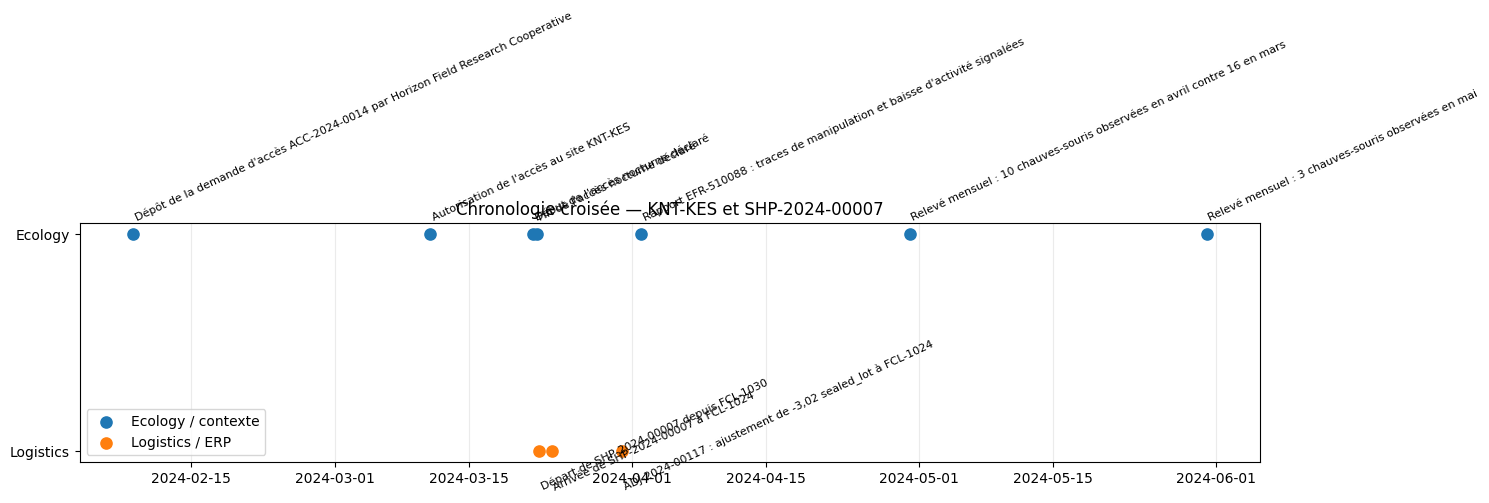

Délai entre fin de l'accès nocturne et départ de l'expédition : 6.0 heures


In [9]:
# Chronologie croisée : les événements Ecology sont repris du scénario / FINAL_ECOLOGY,
# tandis que les événements Logistics proviennent des tables ERP.
chronologie = pd.DataFrame([
    {"date": "2024-02-09 00:00", "domaine": "Ecology / contexte", "événement": "Dépôt de la demande d'accès ACC-2024-0014 par Horizon Field Research Cooperative"},
    {"date": "2024-03-11 00:00", "domaine": "Ecology / contexte", "événement": "Autorisation de l'accès au site KNT-KES"},
    {"date": "2024-03-21 18:00", "domaine": "Ecology / contexte", "événement": "Début de l'accès nocturne déclaré"},
    {"date": "2024-03-22 03:00", "domaine": "Ecology / contexte", "événement": "Fin de l'accès nocturne déclaré"},
    {"date": "2024-03-22 09:00", "domaine": "Logistics / ERP", "événement": "Départ de SHP-2024-00007 depuis FCL-1030"},
    {"date": "2024-03-23 16:00", "domaine": "Logistics / ERP", "événement": "Arrivée de SHP-2024-00007 à FCL-1024"},
    {"date": "2024-03-31 00:00", "domaine": "Logistics / ERP", "événement": "ADJ-2024-00117 : ajustement de -3,02 sealed_lot à FCL-1024"},
    {"date": "2024-04-02 00:00", "domaine": "Ecology / contexte", "événement": "Rapport EFR-510088 : traces de manipulation et baisse d'activité signalées"},
    {"date": "2024-04-30 00:00", "domaine": "Ecology / contexte", "événement": "Relevé mensuel : 10 chauves-souris observées en avril contre 16 en mars"},
    {"date": "2024-05-31 00:00", "domaine": "Ecology / contexte", "événement": "Relevé mensuel : 3 chauves-souris observées en mai"},
])
chronologie["date"] = pd.to_datetime(chronologie["date"], format="mixed", errors="coerce")
display(chronologie)

fig, ax = plt.subplots(figsize=(15, 5))
y = {"Ecology / contexte": 1, "Logistics / ERP": 0}
for domaine, g in chronologie.groupby("domaine"):
    ax.scatter(g["date"], [y[domaine]] * len(g), s=65, label=domaine)
    for _, r in g.iterrows():
        ax.annotate(
            r["événement"], (r["date"], y[domaine]),
            xytext=(0, 10 if domaine.startswith("Ecology") else -28),
            textcoords="offset points", rotation=25, ha="left", fontsize=8
        )
ax.set_yticks([0, 1], ["Logistics", "Ecology"])
ax.set_title("Chronologie croisée — KNT-KES et SHP-2024-00007")
ax.grid(axis="x", alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()

# Intervalle précis entre la fin de l'accès et le départ de l'expédition.
fin_acces = pd.Timestamp("2024-03-22 03:00")
depart_cible = pd.Timestamp("2024-03-22 09:00")
print("Délai entre fin de l'accès nocturne et départ de l'expédition :",
      (depart_cible - fin_acces).total_seconds() / 3600, "heures")


## Synthèse des découvertes — Volet Logistics

### 1. L'expédition ciblée est bien présente dans l'ERP

L'enregistrement `SHP-2024-00007` est confirmé dans `shipments.csv` :

- départ : `FCL-1030`, le 22 mars 2024 à 09 h ;
- destination : `FCL-1024`, le 23 mars 2024 à 16 h ;
- durée du transport : 31 heures ;
- expéditeur : `BP-30056`, Horizon Field Research Cooperative ;
- destinataire : `BP-30078`, Meridian BioLogistics ;
- transporteur : `BP-30047`, Northstar Cold Chain Services ;
- catégorie : `biological_sample` ;
- quantité déclarée : 6 `sealed_lot` ;
- contrôle de température : `2-8C` ;
- statut : `delivered` ;
- motif déclaré : `environmental and wildlife reference materials`.

L'expédition part six heures après la fin de l'accès nocturne déclaré à KNT-KES (21 mars 18 h – 22 mars 03 h). Elle arrive le lendemain, le 23 mars à 16 h. Cette proximité temporelle est réelle, mais elle ne démontre pas que l'expédition est liée matériellement à l'activité menée sur le site écologique.

### 2. L'ajustement est directement rattaché à l'expédition

L'enregistrement `ADJ-2024-00117` confirme :

- date : 31 mars 2024 ;
- site : `FCL-1024`, destination de l'expédition ;
- catégorie : `biological_sample` ;
- quantité : `−3,02 sealed_lot` ;
- motif : `transfer posting correction` ;
- statut : `posted` ;
- référence d'expédition : `SHP-2024-00007`.

L'ajustement est enregistré huit jours après l'arrivée et référence explicitement l'expédition. La valeur absolue de l'ajustement représente 50,3 % de la quantité déclarée expédiée (3,02 / 6). Il s'agit d'un rapport arithmétique entre deux quantités exprimées dans la même unité, et non d'une preuve que la moitié du lot aurait disparu ou été prélevée.

Un point important : le champ `related_receipt_number` de cet ajustement est vide. L'ajustement est donc relié à l'expédition, mais pas à un numéro de réception dans cette table.

### 3. Les référentiels précisent les acteurs et les sites

Les référentiels ERP donnent les informations suivantes :

- `FCL-1030` : **Kintara Cave Authority Field Depot**, dépôt de terrain, exploité par `BP-30016` (Kintara Cave and Pollinator Authority).
- `FCL-1024` : **Meridian Kintara Biological Aggregation Facility**, entrepôt exploité par `BP-30078` (Meridian BioLogistics).
- `BP-30056` : Horizon Field Research Cooperative, rôle ERP `customer` ; c'est l'expéditeur de l'expédition ciblée.
- `BP-30047` : Northstar Cold Chain Services, rôle `carrier` ; c'est le transporteur de l'expédition.
- `BP-30078` : Meridian BioLogistics, rôle `carrier` dans le référentiel ; c'est le destinataire et l'opérateur du site FCL-1024.

Les coordonnées des deux installations sont proches dans le Kintara Karst Cluster : environ 11,3 km à vol d'oiseau entre FCL-1030 et FCL-1024. Cette distance concerne uniquement les deux installations logistiques. **Aucune ligne du référentiel consulté ne permet d'identifier KNT-KES à FCL-1030 ou FCL-1024.** Le lien géographique entre le site écologique et l'une des installations reste donc à établir.

### 4. La réception n'est pas documentée dans la table consultée

La recherche dans `goods_receipts.csv` ne trouve pas de réception associée à `FCL-1024` dans la fenêtre du 20 mars au 15 avril 2024. Le champ `related_receipt_number` de l'ajustement est également vide.

Cette absence de réception correspondante constitue une **lacune de traçabilité documentaire** dans les tables consultées. Elle ne prouve pas que le lot n'a pas été reçu : la réception peut être enregistrée dans une autre table, sous un autre site, ou ne pas être reliée à l'expédition dans le jeu de données.

### 5. Mise en perspective avec les résultats d'inventaire

Le notebook `InventoryNotebook` a rapproché les mouvements mensuels de stock et les expéditions par site, mois et catégorie. Ses résultats globaux indiquent :

- 18 lignes d'inventaire liées à une expédition wildlife ;
- 16 de ces 18 lignes ont un écart de stock négatif ;
- l'écart cumulé de ce groupe est de `−131,0` ;
- l'écart moyen est de `−7,28`, contre `+0,01` pour les lignes sans expédition le même mois ;
- pour `FCL-1024 / biological_sample`, 7 lignes sont liées à une expédition wildlife, avec un écart moyen de `−4,65` ;
- pour les 13 lignes de cette même série sans lien wildlife, l'écart moyen est de `+2,71`.

Ces résultats renforcent l'intérêt d'examiner les mouvements de matériel biologique à FCL-1024. Ils restent toutefois des agrégats mensuels portant sur plusieurs expéditions et plusieurs périodes. Ils ne permettent pas d'attribuer à `SHP-2024-00007` un déficit précis sans isoler la ligne d'inventaire du mois d'arrivée et vérifier les mouvements correspondants.

Par ailleurs, les résultats d'anomalies statistiques du notebook Inventory ne doivent pas être confondus avec une preuve de perte physique : un écart comptable et une anomalie statistique sont deux notions différentes.

### 6. Convergence avec le volet Ecology

Le volet Ecology rapporte un accès nocturne à KNT-KES les 21–22 mars, puis le rapport `EFR-510088` du 2 avril qui mentionne des traces de manipulation et une baisse de l'activité d'*Eonycteris spelaea*. Les observations passent de 16 individus en mars à 10 en avril, puis à 3 en mai.

Le volet Logistics établit indépendamment qu'une expédition de matériel biologique, déclarée comme liée à des « environmental and wildlife reference materials », quitte FCL-1030 le 22 mars à 09 h, soit six heures après la fin de l'accès nocturne. Elle arrive à FCL-1024 le 23 mars, puis fait l'objet d'un ajustement négatif le 31 mars.

La concordance temporelle et le motif déclaré rendent le rapprochement pertinent. Cependant, aucun champ de l'expédition ne mentionne *Eonycteris spelaea*, des chauves-souris ou KNT-KES. Les données ne démontrent donc ni le contenu taxonomique du lot, ni un lien causal avec la baisse des observations.

### Conclusion — Hypothèse logistique compatible

Les résultats corrigés confirment une séquence documentaire précise : **accès nocturne déclaré à KNT-KES → six heures plus tard, départ d'une expédition de six lots de matériel biologique depuis FCL-1030 → arrivée à FCL-1024 → ajustement négatif de 3,02 lots huit jours après l'arrivée**.

Trois éléments rendent cette séquence digne d'investigation :
1. le motif de l'expédition mentionne explicitement des références environnementales et wildlife ;
2. l'ajustement est directement lié à l'expédition, mais aucun numéro de réception n'est renseigné ;
3. les analyses globales d'inventaire montrent des écarts négatifs plus fréquents pour les lignes liées aux expéditions wildlife, y compris dans la série `FCL-1024 / biological_sample`.

**L'hypothèse la plus défendable est donc celle d'une possible connexion opérationnelle entre l'activité nocturne à KNT-KES et un flux logistique de matériel biologique, avec une traçabilité de réception incomplète.** Les données disponibles ne permettent pas d'affirmer que le lot contenait des chauves-souris, qu'il provenait de KNT-KES ou qu'il explique la baisse des observations écologiques.


